# 🎓 Logistic Regression: Predicting Pass or Fail from Study Hours

Welcome! In this notebook, we will explore **Logistic Regression** for classification.

### 💡 What is Logistic Regression?
Despite its name, **Logistic Regression is used for classification** (predicting categories like Pass/Fail, Yes/No, or Spam/Not Spam).

Instead of a straight line, it produces an **S-shaped curve** (Sigmoid function) that calculates the **probability (between 0% and 100%)** of an outcome:
- If probability $\ge 0.5$ (50%), we predict **Pass (1)**.
- If probability $< 0.5$ (50%), we predict **Fail (0)**.

## Step 1: Import Required Libraries

We import scikit-learn tools for Logistic Regression and evaluation metrics, plus matplotlib for plotting.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score
)

print("Libraries successfully imported!")

Libraries successfully imported!


## Step 2: Everyday Student Data (Study Hours vs. Pass/Fail)

Here is data from 20 students:
- **Study Hours:** Hours spent studying per week ($X$)
- **Result:** `0` for Fail, `1` for Pass ($y$)

In [2]:
hours = np.array([
    1.0, 1.5, 2.0, 2.5, 3.0, 3.2, 3.5, 4.0, 4.2, 4.5,
    4.8, 5.2, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0
]).reshape(-1, 1)

results = np.array([
    0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
    0, 1, 1, 1, 1, 1, 1, 1, 1, 1
])

print(f"{'Study Hours':<15}{'Result':<15}")
print("-" * 30)
for h, r in zip(hours.flatten(), results):
    label = "Pass (1)" if r == 1 else "Fail (0)"
    print(f"{h:<15.1f}{label:<15}")

Study Hours    Result         
------------------------------
1.0            Fail (0)       
1.5            Fail (0)       
2.0            Fail (0)       
2.5            Fail (0)       
3.0            Fail (0)       
3.2            Fail (0)       
3.5            Fail (0)       
4.0            Fail (0)       
4.2            Fail (0)       
4.5            Pass (1)       
4.8            Fail (0)       
5.2            Pass (1)       
5.5            Pass (1)       
6.0            Pass (1)       
6.5            Pass (1)       
7.0            Pass (1)       
7.5            Pass (1)       
8.0            Pass (1)       
8.5            Pass (1)       
9.0            Pass (1)       


## Step 3: Visualize the Student Data

Let's see how students who study more hours shift from failing to passing.

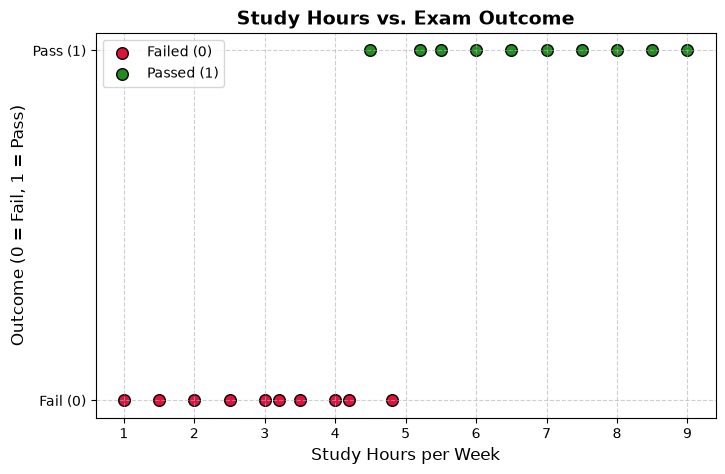

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(hours[results == 0], results[results == 0], color='crimson', s=70, edgecolors='black', label='Failed (0)')
plt.scatter(hours[results == 1], results[results == 1], color='forestgreen', s=70, edgecolors='black', label='Passed (1)')
plt.title('Study Hours vs. Exam Outcome', fontsize=14, fontweight='bold')
plt.xlabel('Study Hours per Week', fontsize=12)
plt.ylabel('Outcome (0 = Fail, 1 = Pass)', fontsize=12)
plt.yticks([0, 1], ['Fail (0)', 'Pass (1)'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Step 4: Train the Logistic Regression Model

We split our data (70% train, 30% test) and train the classifier.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(hours, results, test_size=0.3, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

print("Logistic Regression model successfully trained!")

Logistic Regression model successfully trained!


## Step 5: The Sigmoid Curve (Probability of Passing)

The model fits an S-curve showing the probability of passing based on study hours.
Notice the **decision boundary at 50% (0.5)**.

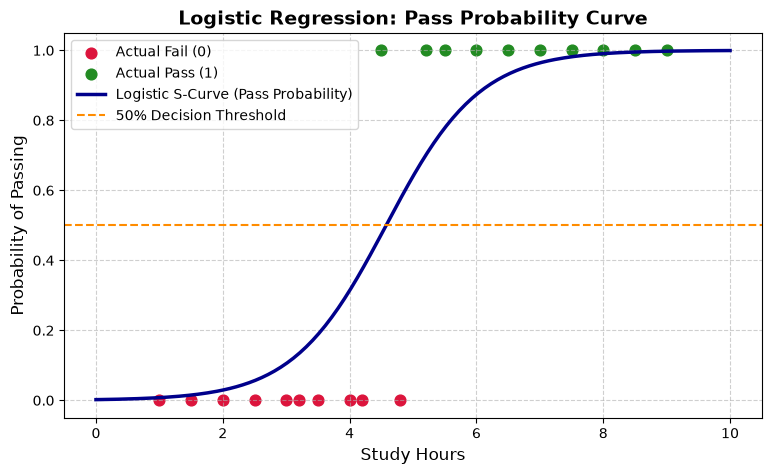

In [5]:
x_curve = np.linspace(0, 10, 200).reshape(-1, 1)
probs = model.predict_proba(x_curve)[:, 1] # Probability of Pass (Class 1)

plt.figure(figsize=(9, 5))
plt.scatter(hours[results == 0], results[results == 0], color='crimson', s=60, label='Actual Fail (0)')
plt.scatter(hours[results == 1], results[results == 1], color='forestgreen', s=60, label='Actual Pass (1)')
plt.plot(x_curve, probs, color='darkblue', linewidth=2.5, label='Logistic S-Curve (Pass Probability)')

plt.axhline(0.5, color='darkorange', linestyle='--', linewidth=1.5, label='50% Decision Threshold')
plt.title('Logistic Regression: Pass Probability Curve', fontsize=14, fontweight='bold')
plt.xlabel('Study Hours', fontsize=12)
plt.ylabel('Probability of Passing', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Step 6: Test Everyday Queries

Let's predict outcomes for two new students:
- **Student A:** Studies 2.5 hours
- **Student B:** Studies 6.5 hours

In [6]:
test_students = np.array([[2.5], [6.5]])
predicted_classes = model.predict(test_students)
predicted_probabilities = model.predict_proba(test_students)[:, 1]

for h, pred, prob in zip(test_students.flatten(), predicted_classes, predicted_probabilities):
    verdict = "PASS" if pred == 1 else "FAIL"
    print(f"Student studying {h:.1f} hours:")
    print(f" - Probability of passing: {prob * 100:.1f}%")
    print(f" - Final Model Decision:   {verdict}\n")

Student studying 2.5 hours:
 - Probability of passing: 5.6%
 - Final Model Decision:   FAIL

Student studying 6.5 hours:
 - Probability of passing: 93.2%
 - Final Model Decision:   PASS



## Step 7: Confusion Matrix Explained Simply

A **Confusion Matrix** is a 2x2 comparison grid showing how the model's predictions match reality:

| | Predicted Fail | Predicted Pass |
|---|---|---|
| **Actually Failed** | **True Negative (TN)** ✅ | **False Positive (FP)** ❌ *(False alarm)* |
| **Actually Passed** | **False Negative (FN)** ❌ *(Missed student)* | **True Positive (TP)** ✅ |

Let's compute and plot it on our test dataset:

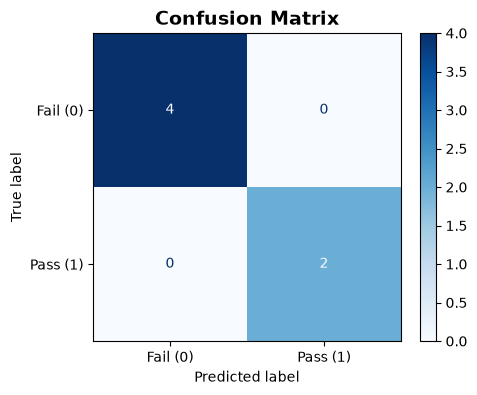

Confusion Matrix Breakdown:
 - True Negatives  (TN): 4 (Actually failed, predicted fail - Correct)
 - False Positives (FP): 0 (Actually failed, predicted pass - Mistake)
 - False Negatives (FN): 0 (Actually passed, predicted fail - Mistake)
 - True Positives  (TP): 2 (Actually passed, predicted pass - Correct)


In [7]:
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail (0)', 'Pass (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.show()

tn, fp, fn, tp = cm.ravel()
print("Confusion Matrix Breakdown:")
print(f" - True Negatives  (TN): {tn} (Actually failed, predicted fail - Correct)")
print(f" - False Positives (FP): {fp} (Actually failed, predicted pass - Mistake)")
print(f" - False Negatives (FN): {fn} (Actually passed, predicted fail - Mistake)")
print(f" - True Positives  (TP): {tp} (Actually passed, predicted pass - Correct)")

## Step 8: Accuracy, Precision, and Recall Explained Simply

### 1. 🎯 Accuracy
- **Simple meaning:** Out of all students tested, what percentage did the model predict correctly?
- **Formula:** $\frac{\text{Correct Predictions}}{\text{Total Students}} = \frac{\text{TP} + \text{TN}}{\text{Total}}$

### 2. 🔍 Precision
- **Simple meaning:** When the model says a student will **PASS**, how often is it actually right?
- **Formula:** $\frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}} = \frac{\text{TP}}{\text{TP} + \text{FP}}$
- *High precision means very few false alarms.*

### 3. 📢 Recall
- **Simple meaning:** Out of all students who **actually passed**, how many did the model successfully catch?
- **Formula:** $\frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}} = \frac{\text{TP}}{\text{TP} + \text{FN}}$
- *High recall means we rarely miss students who passed.*

In [8]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)

print("=" * 40)
print(f"Accuracy:  {acc * 100:.1f}%  (Overall percentage of correct guesses)")
print(f"Precision: {prec * 100:.1f}%  (Reliability when predicting Pass)")
print(f"Recall:    {rec * 100:.1f}%  (Coverage of all students who passed)")
print("=" * 40)

Accuracy:  100.0%  (Overall percentage of correct guesses)
Precision: 100.0%  (Reliability when predicting Pass)
Recall:    100.0%  (Coverage of all students who passed)


## 🎉 Key Takeaways
- **Logistic Regression** is used for classification by estimating probabilities.
- The **Confusion Matrix** shows where mistakes happen (False Positives vs False Negatives).
- **Accuracy** measures overall correctness, **Precision** measures trustworthiness of positive predictions, and **Recall** measures how many actual positives were caught.